[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RobMulla/torchtpu-inference-workshop/blob/main/notebooks/02_sglang_torchtpu.ipynb)

# SGLang on TorchTPU, one chip

Demo 2 of the workshop *Inference with TorchTPU* (TorchTPU DevLabs, Nov 9, 2026), part 3,
**vLLM and SGLang on TorchTPU.** The live demo served `Qwen/Qwen3-32B` with SGLang on four
chips and asked one long prompt about twice, to show the prefix cache; this notebook does
the same with `Qwen/Qwen3-0.6B` on one chip.

What it does, in order: install the engine in an environment of its own, start the
server in the background, wait for `/health`, look at the chip, send one request, send a
burst of sixteen, ask twice about one long prompt, then stop the server.

**The model.** `Qwen/Qwen3-0.6B` is ungated (no Hugging Face token), small enough to download
and start in a few minutes, and named by both engines' own lists: SGLang-TorchTPU's
`SUPPORT_MATRIX.md` (its CI model, including the prefix-cache and torch.compile runs) and
vLLM-TorchTPU's `docs/user_guide/supported_models.md` (the Qwen3 dense path). `MODEL` is one
variable below.

**What the engine manages for you: the KV cache.** Every new token attends to every
token before it; the keys and values of the earlier tokens never change, so the engine
keeps them in HBM between steps instead of recomputing them. Part 2 of the session is
about that cache; part 3 is what the engines do with it (pages, prefix reuse,
batching), which is what this notebook shows on one chip.

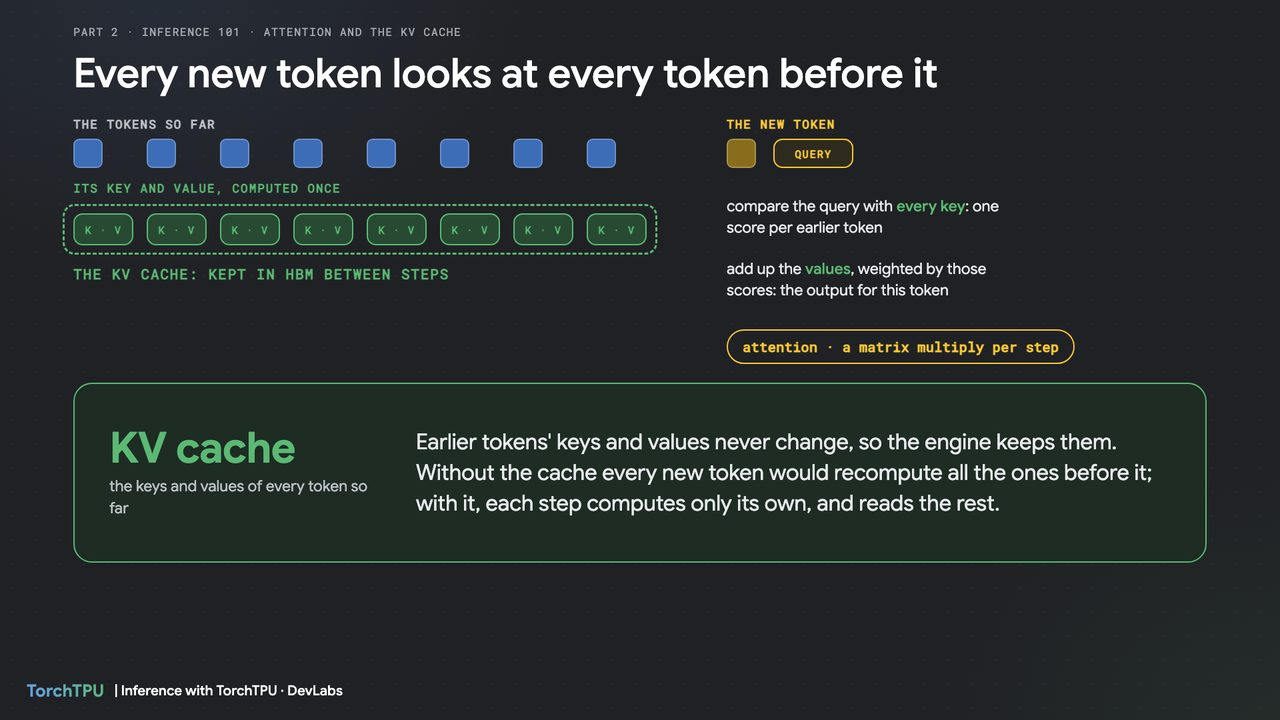

**One chip, one engine.** Both serving notebooks take the whole chip. Run the last cell
(stop) of one before starting the other, or restart the runtime. In Colab, do not run the
first notebook in the same runtime first: its kernel holds the chip.

> **Where this was tested.** On a Cloud TPU v6e-1 (one Trillium chip, 32 GB HBM), run top to
> bottom with `jupyter nbconvert --execute`, from a Python 3.13 kernel like Colab's (Nov 8).
> Colab's TPU runtime is a different chip, so timings and memory differ; the shape of what
> you see does not.

## 1. Install

What you are looking at: SGLang-TorchTPU ships as two wheels on its GitHub release page,
the engine (`sglang`, this repository's build, not the PyPI package) and the TPU plugin
(`sglang_tpu`), installed together with the README's line.

**The server gets a Python 3.12 environment of its own**, made with `uv`. The engines'
wheels are built for Python 3.12 and pin their own torch, `torch_tpu`, `libtpu` and jax;
Colab's kernel is a newer Python with its own packages. So the install line goes into
`venv-sglang` next to this notebook, and the kernel stays the client: it needs only
`openai` and `requests`, and never imports torch. Idempotent: if the environment exists,
nothing is installed. The first time, a few minutes of downloads.

In [ ]:
import importlib.util, os, shutil, subprocess, sys

VENV = os.path.abspath("venv-sglang")  # the server's own Python 3.12 environment
PY = os.path.join(VENV, "bin", "python")
REL = "https://github.com/sgl-project/sglang-torchtpu/releases/download/tpu-v0.1.0"

if shutil.which("uv") is None:
    %pip install -q uv
UV = shutil.which("uv") or os.path.join(os.path.dirname(sys.executable), "uv")
if not os.path.exists(PY):
    print("making", VENV, "and installing SGLang-TorchTPU into it (a few minutes the first time)")
    subprocess.run([UV, "venv", "-q", "--python", "3.12", VENV], check=True)
    subprocess.run([UV, "pip", "install", "-q", "--python", PY,
                    "--index-strategy", "unsafe-best-match",  # the best version across both indexes
                    "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                    f"{REL}/sglang-0.5.22-py3-none-any.whl",
                    f"{REL}/sglang_tpu-0.1.0-py3-none-any.whl", "tpu-info"], check=True)
%pip install -q openai requests

print(subprocess.run([PY, "-c", "import importlib.metadata as md, sys\n"
                      "print('python      ', sys.version.split()[0])\n"
                      "for p in ['sglang', 'sglang-tpu', 'torch', 'torch_tpu', 'libtpu']:\n"
                      "    print(f'{p:12s}', md.version(p))"],
                     capture_output=True, text=True).stdout)

assert subprocess.run([PY, "-c", "import sglang, sglang_tpu"], capture_output=True).returncode == 0, (
    "SGLang-TorchTPU is not in the environment (an empty placeholder install?): rm -rf " + VENV + " and run this cell again")

## 2. Start the server

What you are looking at: `python -m sglang.launch_server` with `--device tpu` and the
flags the live demo used, sized down: one chip (`--tp-size 1`), an 8,192-token context,
up to 8 running requests, 128-token pages, 85% of HBM reserved for weights and KV cache,
`--enable-torch-compile` (the forward passes compiled with `torch.compile`) and
`--enable-cache-report` (so each response says how many prompt tokens came from the
prefix cache; section 7 needs it). The environment lines are from the repository's own
serving environment (`benchmark/tpu/common_env.sh`): `SGLANG_PLATFORM=tpu` selects the
TPU plugin.

`--page-size 128` is paged attention: the KV cache is kept in fixed pages with a table
per request, like an operating system's virtual memory, so nothing is reserved up front
and nothing is wasted; on a TPU the engines run a *ragged* version of the kernel,
fixed-shape programs over the pages, so a mixed batch is one kernel with no padding and
no recompile per shape. The session's slide:

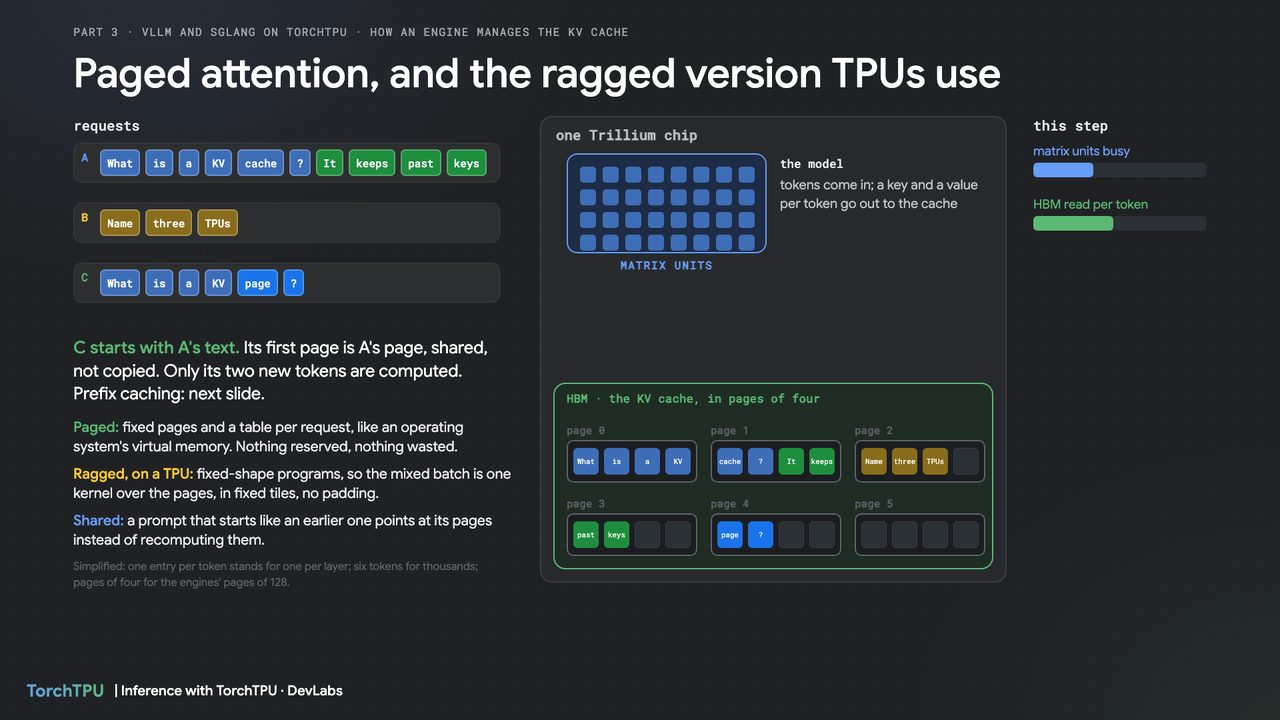

The server is started with `subprocess.Popen` from the environment's Python, in its own
session (`start_new_session`), logging to `sglang_server.log`, so the notebook keeps
running while it loads and the stop cell can signal the whole process group at the end.

In [ ]:
import time

MODEL = "Qwen/Qwen3-0.6B"
PORT = 30000
LOG = os.path.abspath("sglang_server.log")
BASE_URL = f"http://127.0.0.1:{PORT}/v1"

env = dict(os.environ,
           PYTHONUNBUFFERED="1",
           SGLANG_PLATFORM="tpu",
           SGLANG_ALLOW_OVERWRITE_LONGER_CONTEXT_LEN="1",
           TORCH_TPU_INTERNAL_MATERIALIZE_COLLECTIVE_TENSORS="false")

cmd = [PY, "-m", "sglang.launch_server",
       "--model-path", MODEL, "--device", "tpu",
       "--tp-size", "1",
       "--host", "127.0.0.1", "--port", str(PORT),
       "--context-length", "8192", "--max-running-requests", "8",
       "--page-size", "128", "--mem-fraction-static", "0.85",
       "--enable-torch-compile",
       "--enable-cache-report"]
print("python " + " ".join(cmd[1:]))
proc = subprocess.Popen(cmd, env=env, stdout=open(LOG, "w"), stderr=subprocess.STDOUT,
                        stdin=subprocess.DEVNULL, start_new_session=True)
print("pid", proc.pid, "| log", LOG)

## 3. Wait for `/health`

What you are looking at: the server downloads the weights (the first time), loads them
onto the chip, compiles its forward passes and warms up. `/health` answers 200 when it
is ready to serve. The cell prints a line from the log every 30 s so you can see where
it is; on failure it prints the tail of the log.

In [ ]:
import requests

t0 = time.time()
ready, last_print = False, -30
while time.time() - t0 < 1800:
    if proc.poll() is not None:
        break
    try:
        if requests.get(f"http://127.0.0.1:{PORT}/health", timeout=2).status_code == 200:
            ready = True
            break
    except requests.RequestException:  # refused while starting, or /health blocking on a compile
        pass
    if time.time() - t0 - last_print >= 30:
        last_print = time.time() - t0
        with open(LOG) as f:
            lines = f.read().splitlines()
        print(f"[{last_print:5.0f} s] {lines[-1][:110] if lines else ''}")
    time.sleep(1)

START_S = time.time() - t0
if ready:
    print(f"server ready after {START_S:.0f} s")
else:
    print("server not ready; last 40 log lines:")
    with open(LOG) as f:
        print("".join(f.readlines()[-40:]))

## 4. Look at the chip

What you are looking at: `tpu-info` (installed in the server's environment) reads the
chip's HBM use and duty cycle from the TPU runtime. With the server up, the HBM column
shows the weights plus the KV cache the engine reserved. (If the runtime metrics are
unavailable where you run this, the table says N/A; nothing else in the notebook depends
on it.)

In [ ]:
tpu_info = os.path.join(VENV, "bin", "tpu-info")


def show_chip():  # the chip table and the HBM table; the rest is multi-slice metrics
    out = subprocess.run([tpu_info], capture_output=True, text=True).stdout
    print(out.split("TensorCore Utilization")[0].rstrip())


show_chip()

## 5. One request

What you are looking at: the server speaks the OpenAI API, so the client is the stock
`openai` package pointed at `localhost`. One streamed chat completion; the tokens print
as they arrive, then the usage the server reported. `enable_thinking: False` turns off
Qwen3's thinking mode so the answer starts at once. The first request after a start can
take longer than the ones after it (a compile can land here); run the cell twice to see.

In [ ]:
from openai import OpenAI

llm = OpenAI(base_url=BASE_URL, api_key="none")

t0 = time.monotonic()
first = None
stream = llm.chat.completions.create(
    model=MODEL, max_tokens=128,
    messages=[{"role": "user", "content": "In two sentences, what is a KV cache?"}],
    stream=True, stream_options={"include_usage": True},
    extra_body={"chat_template_kwargs": {"enable_thinking": False}})
for chunk in stream:
    for c in chunk.choices:
        if first is None and c.delta.content:
            first = (time.monotonic() - t0) * 1000
        print(c.delta.content or "", end="")
u = chunk.usage  # the last chunk carries the usage
print(f"\n\nfirst token: {first:.0f} ms | prompt {u.prompt_tokens} tokens, "
      f"completion {u.completion_tokens} tokens, {time.monotonic() - t0:.1f} s total")

## 6. A burst of sixteen

What you are looking at: sixteen different questions sent within one second, each
streamed back. The engine batches them on the one chip (continuous batching: requests
join and leave the batch as they arrive and finish). The cell prints each request's
completion tokens and time as it finishes, then the burst's total: completion tokens
over wall time. The number is this machine's, this model's, with these settings, and
nothing more.

In [ ]:
import asyncio
from openai import AsyncOpenAI

N = 16
allm = AsyncOpenAI(base_url=BASE_URL, api_key="none")

asks = ["Explain {} in detail.", "Define {} in one sentence.",
        "List five facts about {}.", "Explain {} in a short paragraph."]
topics = ["torch.compile", "autograd", "nn.Module", "DataLoader", "mixed precision",
          "LayerNorm", "the KV cache", "attention", "dropout", "Adam", "beam search",
          "top-p sampling", "RoPE", "quantization", "tokenizers", "batch norm"]


async def ask(i):
    await asyncio.sleep(i / N)  # arrivals spread over 1 s
    q = asks[i % 4].format(topics[i % 16])
    t0 = time.monotonic()
    stream = await allm.chat.completions.create(
        model=MODEL, max_tokens=256,
        messages=[{"role": "user", "content": q}],
        stream=True, stream_options={"include_usage": True},
        extra_body={"chat_template_kwargs": {"enable_thinking": False}})
    usage = None
    async for chunk in stream:
        if chunk.usage:
            usage = chunk.usage
    dt = time.monotonic() - t0
    print(f"request {i:2d}: {usage.completion_tokens:4d} tokens in {dt:5.1f} s   ({q})")
    return usage.completion_tokens


t_burst = time.monotonic()
tokens = await asyncio.gather(*(ask(i) for i in range(N)))
wall = time.monotonic() - t_burst
BURST_TOK_S = sum(tokens) / wall
print(f"\n{N} requests, {sum(tokens)} completion tokens in {wall:.1f} s "
      f"= {BURST_TOK_S:.0f} tokens/s on this chip")

## 7. The prefix cache

What you are looking at: one long prompt (the source of Python's `json.decoder`
module, with a timestamp in front so the server has never seen it) asked about twice.
For each answer the cell prints the time to the first token and, from the usage the
server returns with `--enable-cache-report`, how many of the prompt's tokens were served from the
prefix cache. The first question has to prefill the whole prompt; the second finds the
prompt's KV cache already there and prefills only the question. This is the
live demo's point on one chip: in a conversation the prompt was mostly seen before, so
with the cache kept, prefill shrinks to the new tokens. Prefix caching is what paging
makes cheap: the second request is pointed at the first one's pages, a pointer, not a
copy. On by default in both engines.

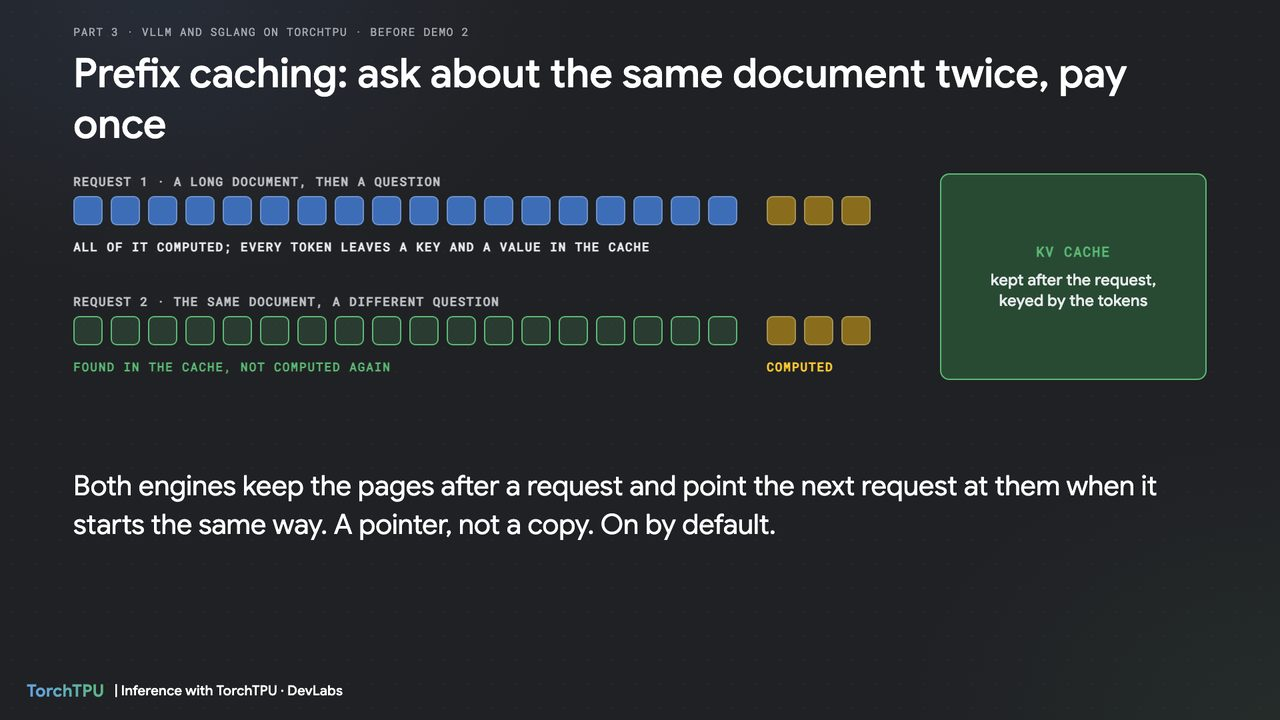

In [ ]:
import inspect
import json.decoder

doc = f"{time.time()}\n" + inspect.getsource(json.decoder)
print(f"prompt: {len(doc):,} characters\n")

for q in ["What does JSONDecodeError record?", "What does raw_decode return?"]:
    print(">", q)
    t0, first = time.monotonic(), None
    stream = llm.chat.completions.create(
        model=MODEL, max_tokens=64,
        messages=[{"role": "user", "content": f"{doc}\n\nIn one sentence: {q}"}],
        stream=True, stream_options={"include_usage": True},
        extra_body={"chat_template_kwargs": {"enable_thinking": False}})
    for chunk in stream:
        for c in chunk.choices:
            if first is None and c.delta.content:
                first = (time.monotonic() - t0) * 1000
            print(c.delta.content or "", end="")
    u = chunk.usage
    d = u.prompt_tokens_details  # None when nothing was cached
    cached = d.cached_tokens if d else 0
    print(f"\nfirst token: {first:.0f} ms, cached {cached:,} of {u.prompt_tokens:,} prompt tokens\n")

## Stop the server

What you are looking at: the server and every process it started share one process
group; one SIGINT to the group stops them all and frees the chip. Run this before
starting the vLLM notebook.

In [ ]:
import signal


def stop_server(proc, timeout=60):
    if proc.poll() is not None:
        print("already stopped, exit code", proc.returncode)
        return
    os.killpg(proc.pid, signal.SIGINT)
    t0 = time.time()
    while proc.poll() is None and time.time() - t0 < timeout:
        time.sleep(1)
    if proc.poll() is None:
        os.killpg(proc.pid, signal.SIGKILL)
        proc.wait()
    print(f"stopped after {time.time() - t0:.0f} s, exit code {proc.returncode}")


stop_server(proc)
time.sleep(3)
show_chip()

## Where to go next

- `github.com/sgl-project/sglang-torchtpu`: the README (install, `launch_server`, the
  serving recipes under `benchmark/tpu/`) and `SUPPORT_MATRIX.md`.
- `03_vllm_torchtpu.ipynb` in this folder serves the same model the same way with vLLM.
- The session's slides are in `slides/` in this repository (one PDF).